# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ameilia Chen, Lawson Pham, Nate Park, Amran Belete

**Date:** 11/16/2026

1. Check out the data set `heart_failure` and appropriately clean it.

In [2]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv', low_memory=False)
print("df.shape:")
print(df.shape, '\n')

print("df.dtypes:")
print(df.dtypes, '\n')


print("Original shape:", df.shape)
print("Exact duplicates:", df.duplicated().sum())
print("Missing values:", df.isna().sum().sum())
print("Outcome counts:")
display(df["DEATH_EVENT"].value_counts().sort_index())

df = df.drop_duplicates().copy()
df = df.apply(pd.to_numeric, errors="raise")
assert df.isna().sum().sum() == 0
assert df["DEATH_EVENT"].isin([0, 1]).all()



df.head()

df.shape:
(299, 13) 

df.dtypes:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object 

Original shape: (299, 13)
Exact duplicates: 0
Missing values: 0
Outcome counts:


DEATH_EVENT
0    203
1     96
Name: count, dtype: int64

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.



In [15]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


X = df.drop(columns=["DEATH_EVENT"])
y = df["DEATH_EVENT"]

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=90
)

seeds = [42, 65, 28, 2]
tree_models = {}
linear_models = {}
metrics = []
coefficients = []
tree_summary = []


prediction = pd.DataFrame({"actual": y_test}, index=y_test.index)
for seed in seeds:
    X_train, _, y_train, _ = train_test_split(
        X_dev, y_dev, test_size=0.20, random_state=seed
    )

    tree = DecisionTreeClassifier(min_samples_leaf=10, random_state=100)
    linear = LogisticRegression(max_iter=1000)

    tree.fit(X_train, y_train)
    linear.fit(X_train, y_train)

    tree_models[seed] = tree
    linear_models[seed] = linear

    for model_name, model in [("tree", tree), ("linear", linear)]:
        predict = model.predict_proba(X_test)[:, 1]
        prediction[f"{model_name}_{seed}"] = predict

        metrics.append({
            "seed": seed,
            "model": model_name,
            "MAE": mean_absolute_error(y_test, predict),
            "RMSE": np.sqrt(mean_squared_error(y_test, predict)),
            "R2": r2_score(y_test, predict)
        })

    coefficients.append({
        "seed": seed,
        "intercept": linear.intercept_[0],
        **dict(zip(X.columns, linear.coef_[0]))
    })

    root_feature = X.columns[tree.tree_.feature[0]]
    tree_summary.append({
        "seed": seed,
        "depth": tree.get_depth(),
        "leaves": tree.get_n_leaves(),
        "root_feature": root_feature,
        "root_threshold": tree.tree_.threshold[0],
    })


metrics = pd.DataFrame(metrics)
coefficients = pd.DataFrame(coefficients).set_index("seed")
tree_summary = pd.DataFrame(tree_summary).set_index("seed")

print("Test-set performance:")
display(metrics.round(3))

print("Linear-model coefficients by seed:")
display(coefficients.round(4))

print("Coefficient standard deviations across seeds:")
display(coefficients.std().rename("standard_deviation").to_frame().round(4))

print("Tree size and root split by seed:")
display(tree_summary.round(3))

print("Predictions for test samples:")
display(prediction.head(10))

Test-set performance:


/Users/ameliachen/Development/ds3001/L03-tree-stability/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/ameliachen/Development/ds3001/L03-tree-stability/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale

,seed,model,MAE,RMSE,R2
0,42,tree,0.281,0.410,0.171
1,42,linear,0.273,0.413,0.160
2,65,tree,0.213,0.358,0.370
3,65,linear,0.283,0.423,0.117
4,28,tree,0.216,0.373,0.313
5,28,linear,0.276,0.414,0.158
6,2,tree,0.201,0.381,0.284
7,2,linear,0.274,0.417,0.143


Linear-model coefficients by seed:


,intercept,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
seed,,,,,,,,,,,,,
42,0.0363,0.0838,0.0568,0.0008,0.2599,-0.0782,-0.2158,0.0,0.3128,-0.0088,-0.3388,-0.1614,-0.0239
65,0.0608,0.0629,-0.3187,0.0002,0.7971,-0.0859,0.0619,-0.0,0.4083,0.0082,-0.2442,-0.2293,-0.0242
28,0.0172,0.0627,0.0307,0.0002,0.0963,-0.0718,0.0518,-0.0,0.5079,0.0023,-0.2461,-0.1677,-0.0236
2,0.0851,0.0444,-0.1456,0.0002,0.6792,-0.0804,-0.0781,-0.0,0.5040,0.0131,-0.4124,-0.1353,-0.0263


Coefficient standard deviations across seeds:


,standard_deviation
intercept,0.0295
age,0.0161
anaemia,0.1746
creatinine_phosphokinase,0.0003
diabetes,0.3336
ejection_fraction,0.0058
high_blood_pressure,0.1305
platelets,0.0000
serum_creatinine,0.0926
serum_sodium,0.0094


Tree size and root split by seed:


,depth,leaves,root_feature,root_threshold
seed,,,,
42,6,10,time,73.5
65,5,9,time,73.5
28,6,10,time,67.0
2,5,9,time,73.5


Predictions for test samples:


,actual,tree_42,linear_42,tree_65,linear_65,tree_28,linear_28,tree_2,linear_2
217,1,0.200000,0.022296,0.300000,0.045960,0.2,0.199259,0.071429,0.091724
213,1,0.100000,0.036163,0.133333,0.079706,0.0,0.063357,0.666667,0.072071
38,0,1.000000,0.972585,1.000000,0.946618,1.0,0.920493,1.000000,0.944537
259,0,0.000000,0.001826,0.000000,0.001889,0.0,0.002855,0.000000,0.001636
267,0,0.200000,0.009349,0.300000,0.022142,0.2,0.017195,0.071429,0.014609
108,0,0.000000,0.428771,0.000000,0.298639,0.0,0.358471,0.000000,0.281990
67,1,1.000000,0.793736,0.800000,0.734391,0.6,0.787198,1.000000,0.714007
296,0,0.181818,0.001587,0.000000,0.000301,0.0,0.000433,0.000000,0.000469
147,0,0.000000,0.127977,0.000000,0.056805,0.0,0.088871,0.000000,0.047200
211,0,0.200000,0.001619,0.300000,0.002615,0.0,0.003933,0.090909,0.002047


The trees we get are similar, having around the same depth and amount of leaves. There is only one outlier, which is a depth of 9 and has 33 leaves, but that is only off by one level. The coefficients are very small, with a standard deviation of .0208.


4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?


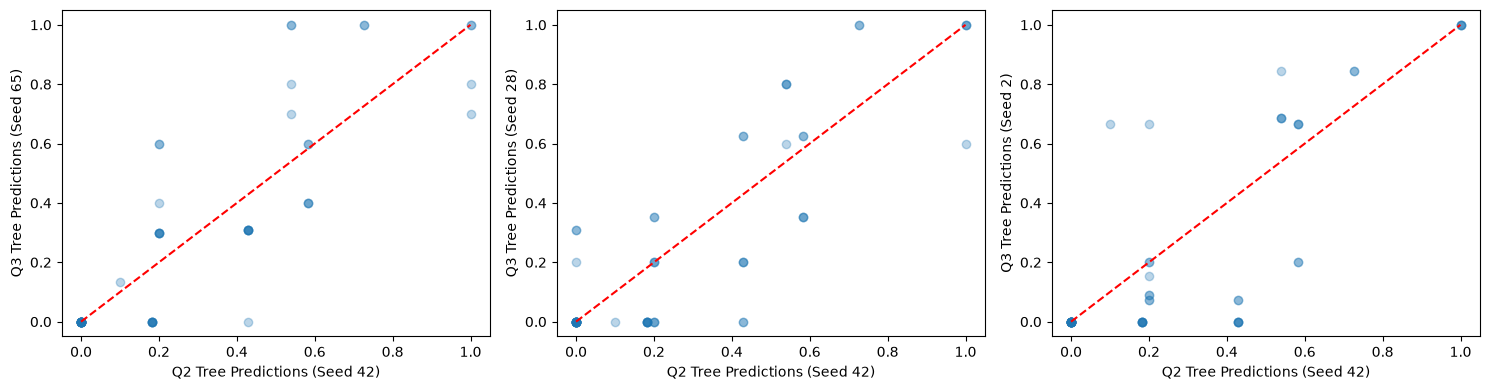

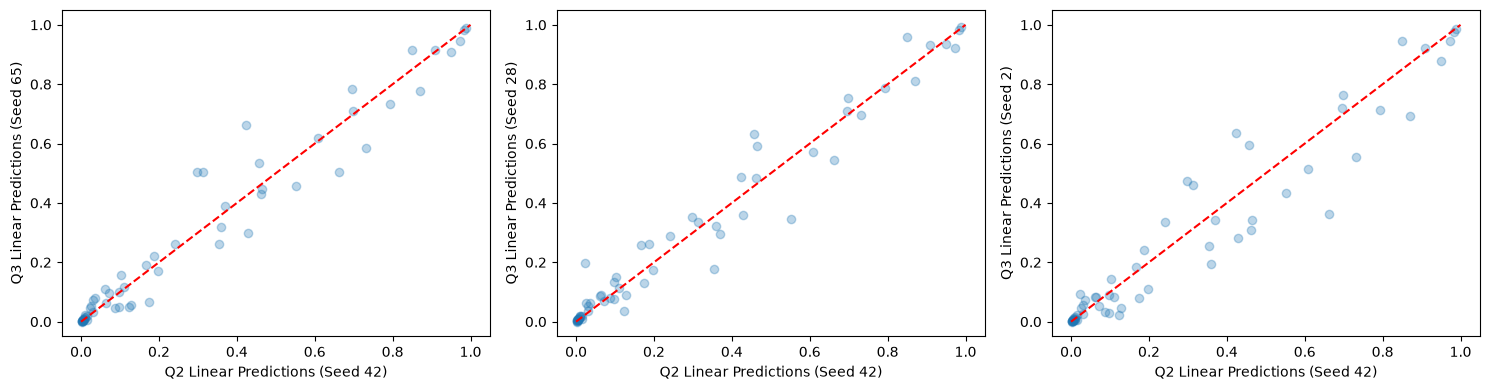

Decision tree correlations: 
{65: np.float64(0.8575275460335611), 28: np.float64(0.8472420085807904), 2: np.float64(0.8179337982162352)}

Linear correlations: 
{65: np.float64(0.9761061226953625), 28: np.float64(0.9799798946191811), 2: np.float64(0.9621296410759976)}

Decision tree regression: 
{'seed': 65, 'intercept': np.float64(0.004815298217725361), 'slope': np.float64(0.9813783334452952), 'R2': 0.7353534922063412}
{'seed': 28, 'intercept': np.float64(-0.013789302021872424), 'slope': np.float64(0.9520943628193946), 'R2': 0.7178190211040119}
{'seed': 2, 'intercept': np.float64(-0.038264463989388375), 'slope': np.float64(0.9487055876197674), 'R2': 0.6690156982644369}

Linear models regression: 
{'seed': 65, 'intercept': np.float64(0.008886159659933723), 'slope': np.float64(0.9683297200226287), 'R2': 0.9527831627633739}
{'seed': 28, 'intercept': np.float64(0.01137170620829403), 'slope': np.float64(0.9736784944568756), 'R2': 0.9603605938578218}
{'seed': 2, 'intercept': np.float64(0.000

In [36]:
from sklearn.linear_model import LinearRegression

# 4a
seeds = {
    0 : 65,
    1 : 28,
    2 : 2,
}


fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, seed in enumerate([0, 1, 2]):
    axes[i].scatter(
        prediction["tree_42"],
        prediction[f"tree_{seeds[i]}"],
        alpha=0.3
    )

    axes[i].set_xlabel("Q2 Tree Predictions (Seed 42)")
    axes[i].set_ylabel(f"Q3 Tree Predictions (Seed {seeds[i]})")
    axes[i].plot([0, 1], [0, 1], 'r--')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, seed in enumerate([0, 1, 2]):
    axes[i].scatter(
        prediction["linear_42"],
        prediction[f"linear_{seeds[i]}"],
        alpha=0.3
    )

    axes[i].set_xlabel("Q2 Linear Predictions (Seed 42)")
    axes[i].set_ylabel(f"Q3 Linear Predictions (Seed {seeds[i]})")
    axes[i].plot([0, 1], [0, 1], 'r--')

plt.tight_layout()
plt.show()


# 4b
tree_correlations = {}

for seed in [65, 28, 2]:
    corr = prediction["tree_42"].corr(prediction[f"tree_{seed}"])
    tree_correlations[seed] = corr

print("Decision tree correlations: ")
print(tree_correlations)
print()

linear_correlations = {}

for seed in [65, 28, 2]:
    corr = prediction["linear_42"].corr(prediction[f"linear_{seed}"])
    linear_correlations[seed] = corr

print("Linear correlations: ")
print(linear_correlations)
print()


# 4c
tree_regression_summary = []

for seed in [65, 28, 2]:
    X = prediction[["tree_42"]]
    y = prediction[f"tree_{seed}"]
    regr = LinearRegression()
    regr.fit(X, y)

    tree_regression_summary.append({
        "seed": seed,
        "intercept": regr.intercept_,
        "slope": regr.coef_[0],
        "R2": regr.score(X, y)
    })

print("Decision tree regression: ")
print(*tree_regression_summary, sep='\n')
print()


linear_regression_summary = []

for seed in [65, 28, 2]:
    X = prediction[["linear_42"]]
    y = prediction[f"linear_{seed}"]
    regr = LinearRegression()
    regr.fit(X, y)

    linear_regression_summary.append({
        "seed": seed,
        "intercept": regr.intercept_,
        "slope": regr.coef_[0],
        "R2": regr.score(X, y)
    })

print("Linear models regression: ")
print(*linear_regression_summary, sep='\n')


##### 4a. Do they appear reasonably similar?
We plot our Q2 seed on the x axis and compare it to each additional seed on the y axis. As such, the y=x line represents where the points would lie if the models predicted similarly. For our decision tree scatterplots, we observe that the points are similar to the extent that they follow the general path of the y=x line, and there are no points in the top left and bottom right corners. The points themselves appear in different patterns in each scatterplot, and they are quite spread out. On the other hand, for the linear model scatterplots, the points are much closer to the y=x line. The results are more consistent, with all three plots showing a denser cluster of points at the (0,0) mark. The rest of the points are spread out relatively evenly across the length of the y=x line. We also observe that the points are tighter around the ends of the y=x line, at (0,0) and (1,1), while the points in the section in between are more spread out.
    
##### 4b. Are they highly correlated or not?
The decision tree correlations were 0.858, 0.847, and 0.818 respectively. As the scale for correlation ranges from -1 to 1, the decision trees can be considered moderately to highly correlated. We observe a greater variety between the correlations, with the greatest difference being between 0.858 and 0.818, a difference of 0.04. The linear models correlations were 0.976, 0.980, and 0.962 respectively. The linear models are very highly correlated, reaching very close to 1. In contrast, the greatest difference between correlations is between 0.962 and 0.980, a difference of 0.018. The greatest difference between the decision tree correlation is more than twice as large than that of the linear model correlations.
    
##### 4c. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?
For the decision trees, the intercepts are quite close to 0. The intercept closest to zero was 0.0048, while the intercept furthest from zero was -0.383. We notice that one of the intercepts is positive while two are negative. The slopes are also quite close to 1, with the closest slope being 0.9814 and the furthest slope being 0.9487. However, the R2 is not as close to 1, with the best R2 being 0.7354 and the worst R2 being 0.6690. For the linear models, the intercepts are also quite close to 0. The closest was 0.0006 while the furthest was 0.0114. All intercepts were positive. The slopes are again close to 1, with the closest being 0.9737 and the furthest being 0.9377. For the R2, it is also close to 1, with the best score being 0.9604 and the worst being 0.9257. Overall, in comparison, the linear models had better intercepts with a small range across seed variations. For slopes, decision trees performed slightly better and both had similar ranges in values. Lastly, for R2, linear models scored significantly closer to 1.





5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?


Yes, the linear models similar across the splits and the predictions are almost the same. They correlate 0.96 to 0.98 with the seed 42 model, and the dots in the scatterplots sit right on the diagonal line. The coefficients for the important variables (which are time, ejection Fraction, and serum creatinine) barely change, although some of the smaller ones jump around. Diabetes goes from about 0.10 to 0.80, and anemia switches between positive and negative. The model isn’t sure about those variables, but that doesn’t fully change what it predicts. For trees, its not as similar. The correlations are lower (0.82 to 0.86), and the dots in the scatterplots are more spread out and farther from the line. The trees do look alike in some ways, because all four split on time first and they’re about the same size. But for individual patients they can disagree a lot. For patient 213, the four trees predict 0.10, 0.13, 0.00 and 0.67, while the four linear models all predict between 0.04 and 0.08. Overall, The linear models are more consistent than the trees, in both predictions and coefficients

6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

True for this dataset. The linear model coefficients change between splits, and some even flip sign. Even so, the predictions are almost the same. The correlations are 0.96 to 0.98 and the R^2 is about 0.93 to 0.96, with slopes near 1 and intercepts near 0. The trees predictions are also fairly similar (correlations 0.82 to 0.86, slopes near 1, intercepts near 0), just not as similar as the linear models’ (R^2 only 0.67 to 0.74). So models can look different and still predict about the same thing. This is more true for the linear models than for the trees, which is why the word “often” fits. One thing to keep in mind is that agreeing with each other doesn’t mean being right. The models test R^2 against the real outcomes is only about 0.12 to 0.37, so none of them predicts death very well.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. Review my Phase 1 code and answers for the Trees and Model Stability assignment. Find any mistakes, suggest improvements, and explain why each change is needed. Keep the code simple and similar to my original work. Give me a numbered list of suggested changes.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]